# Figure 1. FastRNA workflow

In [1]:
from pathlib import Path

from IPython.display import Image as ShowImage, display
from PIL import Image, ImageOps

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
WORKFLOW = ROOT / "figures" / "main" / "workflow.png"
OUT = ROOT / "figures" / "main" / "figure1.png"

src = Image.open(WORKFLOW)
print(f"source: {WORKFLOW.relative_to(ROOT)}  {src.width}x{src.height}px")
for w in (3.5, 7.0):
    print(f"  at {w} in wide that is {src.width / w:.0f} dpi")


source: figures/main/workflow.png  7823x2293px
  at 3.5 in wide that is 2235 dpi
  at 7.0 in wide that is 1118 dpi


## Figure
FastRNA workflow from structure input through base-pair, backbone and
sugar-pucker assessment to reporting and PyMOL visualization


wrote figures/main/figure1.png  7729x2215px  (25.8 x 7.4 in at 300 dpi)


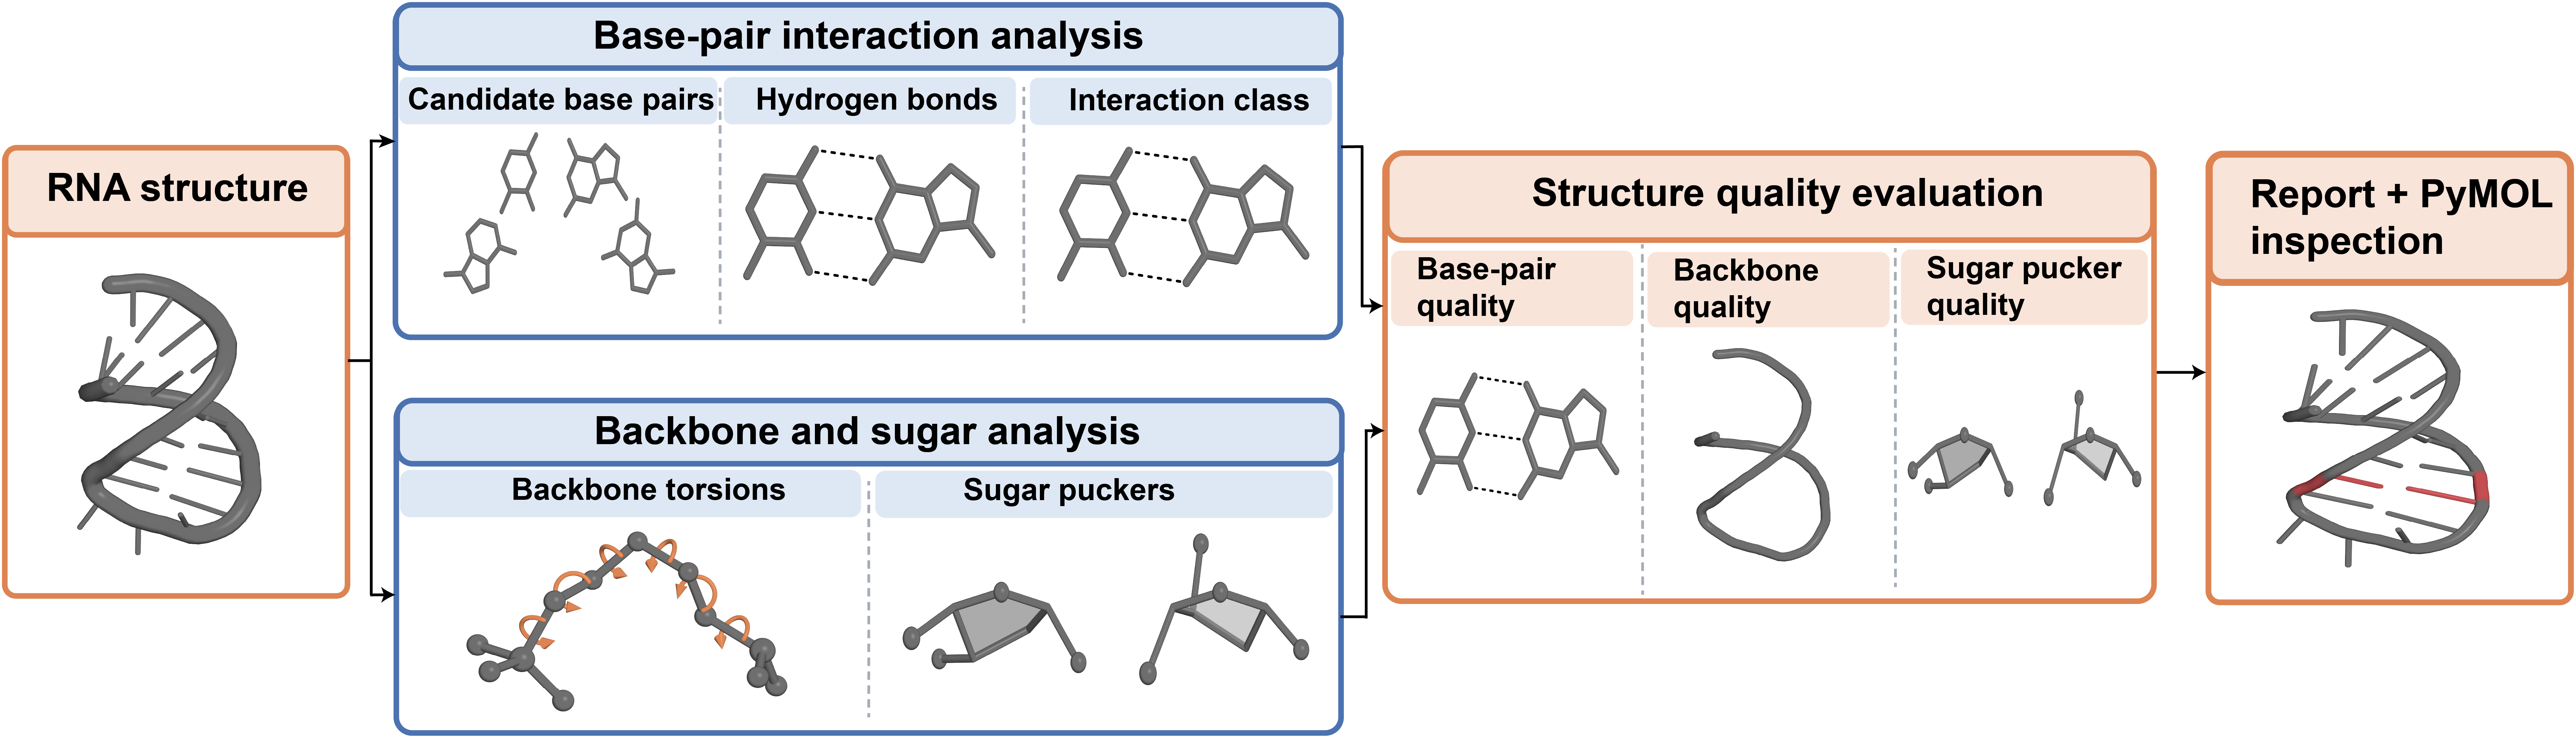

In [2]:
def build(pad=6, thresh=250):
    im = Image.open(WORKFLOW).convert("RGB")
    mask = ImageOps.grayscale(im).point(lambda v: 255 if v < thresh else 0)
    box = mask.getbbox()
    if box:
        l, t, r, b = box
        im = im.crop((max(0, l - pad), max(0, t - pad),
                      min(im.width, r + pad), min(im.height, b + pad)))
    im.save(OUT, dpi=(300, 300))
    return im

fig1 = build()
print(f"wrote {OUT.relative_to(ROOT)}  {fig1.width}x{fig1.height}px  "
      f"({fig1.width/300:.1f} x {fig1.height/300:.1f} in at 300 dpi)")
display(ShowImage(filename=str(OUT)))
